1. Define the prediction problem

        Our objective is:

        Given a crop and information available up to a particular point in time, predict its yield for a future year.

        For example, we want to train a model on earlier observations and evaluate whether it can predict wheat yields for later years.

PHASE 5: FEATURE ENGINNEERING AND PRE PROCESSING


In [2]:
!pip install pandas scikit-learn matplotlib

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
from pathlib import Path

# Load processed data
data_path = Path("../data/processed/india_crop_yield_annual.csv")
annual_df = pd.read_csv(data_path)

# Select columns for the initial forecasting experiment
model_df = annual_df[
    [
        
        "Item",
        "Year",
        "avg_temp",
        "hg_ha_yield"
    ]
].copy()

# Sort chronologically within each crop
model_df = model_df.sort_values(
    ["Year", "Item"]
).reset_index(drop=True)

print("Model dataset shape:", model_df.shape)

print("\nFirst five records:")
display(model_df.head())

print("\nMissing values:")
print(model_df.isnull().sum())

Model dataset shape: (138, 4)

First five records:


,Item,Year,avg_temp,hg_ha_yield
0,Potatoes,1990,25.6,157136
1,"Rice, paddy",1990,25.6,26125
2,Sorghum,1990,25.6,8136
3,Soybeans,1990,25.6,10145
4,Sweet potatoes,1990,25.6,79663



Missing values:
Item           0
Year           0
avg_temp       0
hg_ha_yield    0
dtype: int64


Split the data chronologically

    We'll use this initial experimental split:

        Dataset
        Training set--  1990–2007	(Learn historical )

        Test set--  2008–2013	(Evaluate performance on later years)

In [4]:
# Chronological split
train_df = model_df[
    model_df["Year"] <= 2007
].copy()

test_df = model_df[
    model_df["Year"] >= 2008
].copy()

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print(
    "\nTraining years:",
    train_df["Year"].min(),
    "to",
    train_df["Year"].max()
)

print(
    "Testing years:",
    test_df["Year"].min(),
    "to",
    test_df["Year"].max()
)

print("\nTraining observations per crop:")
print(train_df["Item"].value_counts().sort_index())

print("\nTesting observations per crop:")
print(test_df["Item"].value_counts().sort_index())

Training dataset shape: (102, 4)
Testing dataset shape: (36, 4)

Training years: 1990 to 2007
Testing years: 2008 to 2013

Training observations per crop:
Item
Potatoes          17
Rice, paddy       17
Sorghum           17
Soybeans          17
Sweet potatoes    17
Wheat             17
Name: count, dtype: int64

Testing observations per crop:
Item
Potatoes          6
Rice, paddy       6
Sorghum           6
Soybeans          6
Sweet potatoes    6
Wheat             6
Name: count, dtype: int64


define input(X) and output(Y) features 

In [5]:
# Define input features and target
feature_columns = [
    "Item",
    "Year",
    "avg_temp"
]

target_column = "hg_ha_yield"

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (102, 3)
y_train shape: (102,)
X_test shape: (36, 3)
y_test shape: (36,)


preprocessing pipeline:
ONE-HOT ENCODING

In [6]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical columns
categorical_features = ["Item"]
numerical_features = ["Year", "avg_temp"]

# Create the preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "crop_encoder",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical_features",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing transformer created successfully.")



Preprocessing transformer created successfully.


In [7]:

# Learn the encoding from training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nGenerated feature names:")
print(preprocessor.get_feature_names_out())


Processed training shape: (102, 8)
Processed testing shape: (36, 8)

Generated feature names:
['crop_encoder__Item_Potatoes' 'crop_encoder__Item_Rice, paddy'
 'crop_encoder__Item_Sorghum' 'crop_encoder__Item_Soybeans'
 'crop_encoder__Item_Sweet potatoes' 'crop_encoder__Item_Wheat'
 'numerical_features__Year' 'numerical_features__avg_temp']


BASELINE MODEL:Regression model 

In [8]:
#Instead of using the preprocessor and regression model separately, we'll connect them into a single scikit-learn pipeline.
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create a pipeline that preprocesses data and trains the model
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Baseline model pipeline created successfully.")



Baseline model pipeline created successfully.


In [9]:

# Train using historical training data only
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")


Baseline model trained successfully!


In [10]:

# Predict yields for the test period
y_pred = baseline_model.predict(X_test)

# Display actual and predicted values
results_df = pd.DataFrame({
    "Crop": X_test["Item"].values,
    "Year": X_test["Year"].values,
    "Actual_Yield": y_test.values,
    "Predicted_Yield": y_pred
})

results_df["Predicted_Yield"] = results_df["Predicted_Yield"].round(2)

print("First 10 predictions:")
display(results_df.head(10))



First 10 predictions:


,Crop,Year,Actual_Yield,Predicted_Yield
0,Potatoes,2008,192973,178946.29
1,"Rice, paddy",2008,32509,35113.76
2,Sorghum,2008,10209,14462.82
3,Soybeans,2008,10415,16234.23
4,Sweet potatoes,2008,88943,92083.53
5,Wheat,2008,28022,31725.94
6,Potatoes,2009,188103,176395.64
7,"Rice, paddy",2009,32366,32563.11
8,Sorghum,2009,9621,11912.17
9,Soybeans,2009,10236,13683.58


In [11]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Baseline Model Evaluation")
print("-------------------------")
print(f"MAE:  {mae:.2f} hg/ha")
print(f"RMSE: {rmse:.2f} hg/ha")
print(f"R²:   {r2:.4f}")


Baseline Model Evaluation
-------------------------
MAE:  7575.83 hg/ha
RMSE: 14210.17 hg/ha
R²:   0.9595


In [12]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

# Calculate mean yield for each crop using training data only
crop_mean_yields = (
    train_df.groupby("Item")["hg_ha_yield"].mean()
)

# Predict each test observation using its crop's training mean
baseline_predictions = X_test["Item"].map(crop_mean_yields)

# Evaluate the baseline
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(y_test, baseline_predictions)

print("Crop-Specific Mean Baseline")
print("---------------------------")
print(f"MAE:  {baseline_mae:.2f} hg/ha")
print(f"RMSE: {baseline_rmse:.2f} hg/ha")
print(f"R²:   {baseline_r2:.4f}")



Crop-Specific Mean Baseline
---------------------------
MAE:  9514.77 hg/ha
RMSE: 16880.09 hg/ha
R²:   0.9428


In [13]:

comparison_df = pd.DataFrame({
    "Model": [
        "Crop-Specific Mean Baseline",
        "Linear Regression"
    ],
    "MAE": [
        baseline_mae,
        mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ],
    "R2": [
        baseline_r2,
        r2
    ]
})

display(comparison_df.round(4))



,Model,MAE,RMSE,R2
0,Crop-Specific Mean Baseline,9514.7712,16880.0886,0.9428
1,Linear Regression,7575.8320,14210.1666,0.9595


Evaluate errors separately for each crop

In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Store actual and predicted values alongside crop names
evaluation_df = pd.DataFrame({
    "Crop": X_test["Item"].values,
    "Year": X_test["Year"].values,
    "Actual_Yield": y_test.values,
    "Predicted_Yield": y_pred
})

# Calculate evaluation metrics separately for each crop
crop_results = []

for crop, group in evaluation_df.groupby("Crop"):
    actual = group["Actual_Yield"]
    predicted = group["Predicted_Yield"]

    crop_results.append({
        "Crop": crop,
        "Test_Observations": len(group),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

crop_metrics_df = pd.DataFrame(crop_results)

display(crop_metrics_df.round(2))

,Crop,Test_Observations,MAE,RMSE,R2
0,Potatoes,6,30190.10,33722.60,-3.43
1,"Rice, paddy",6,1012.60,1334.68,0.45
2,Sorghum,6,4786.76,5008.09,-68.86
3,Soybeans,6,4284.34,4608.58,-9.34
4,Sweet potatoes,6,3401.47,4606.35,-0.16
5,Wheat,6,1779.72,2244.87,-1.40


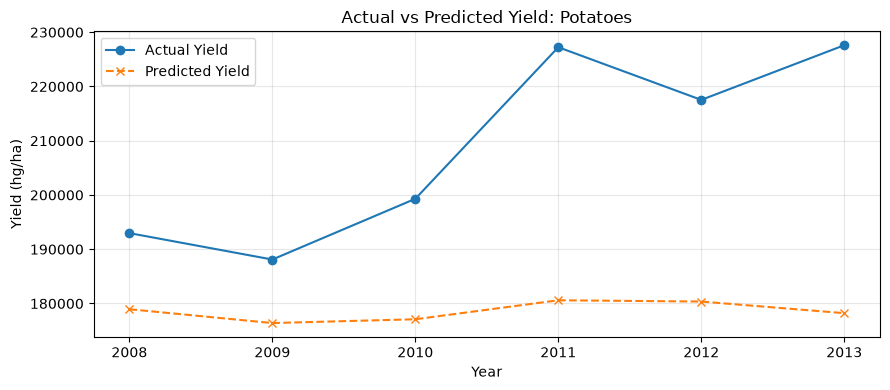

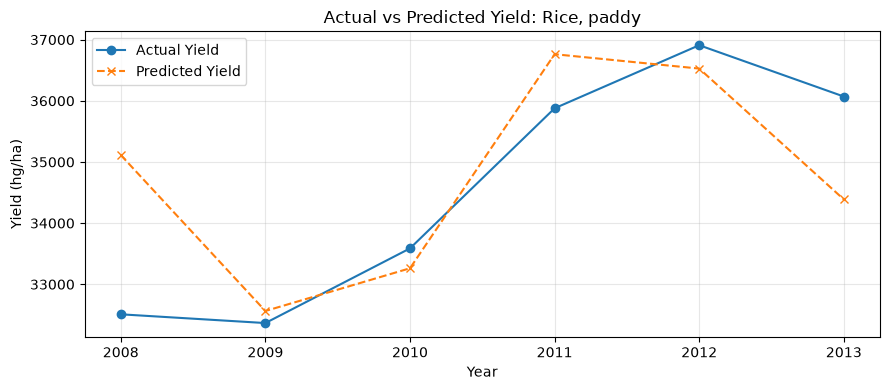

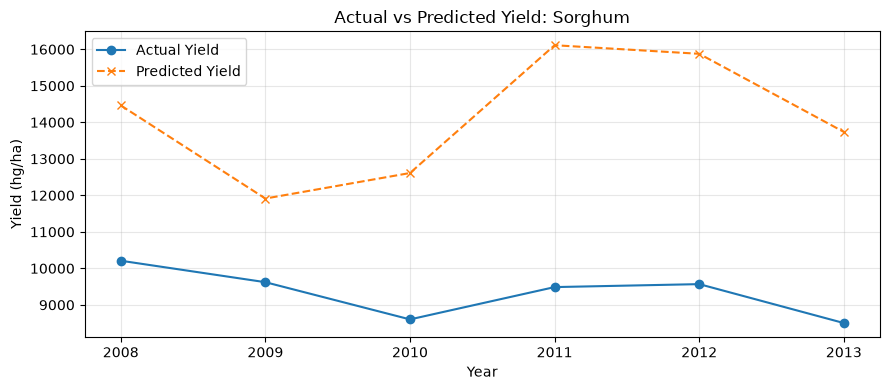

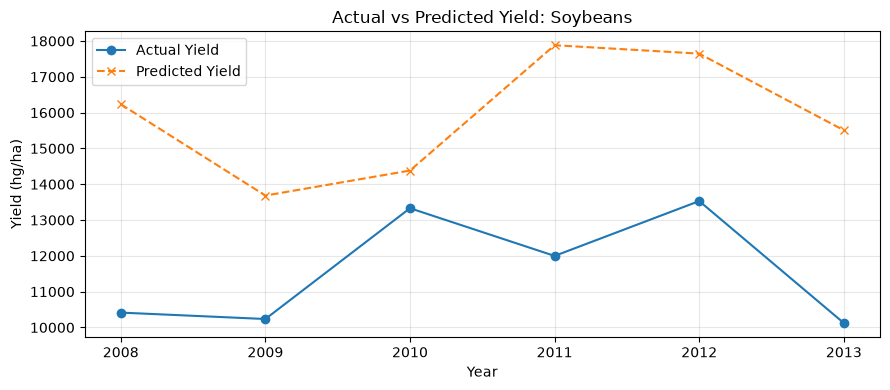

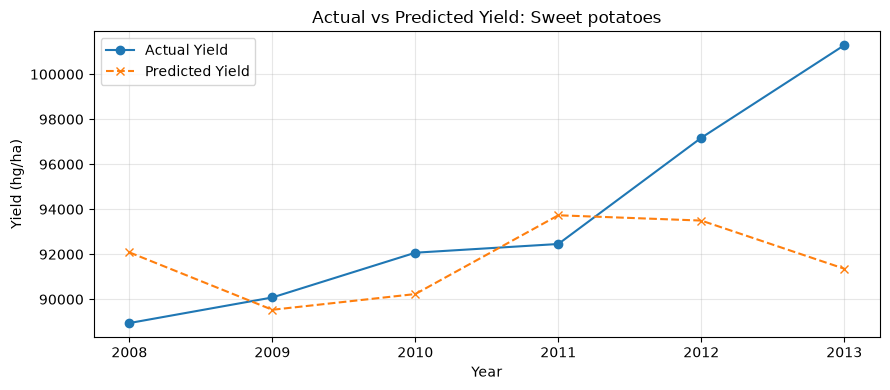

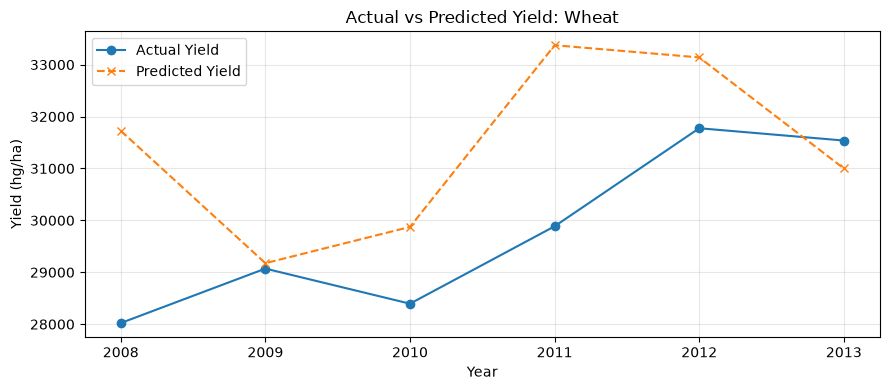

In [15]:
import matplotlib.pyplot as plt

for crop in evaluation_df["Crop"].unique():

    crop_data = evaluation_df[
        evaluation_df["Crop"] == crop
    ].sort_values("Year")

    plt.figure(figsize=(9, 4))

    plt.plot(
        crop_data["Year"],
        crop_data["Actual_Yield"],
        marker="o",
        label="Actual Yield"
    )

    plt.plot(
        crop_data["Year"],
        crop_data["Predicted_Yield"],
        marker="x",
        linestyle="--",
        label="Predicted Yield"
    )

    plt.title(f"Actual vs Predicted Yield: {crop}")
    plt.xlabel("Year")
    plt.ylabel("Yield (hg/ha)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

SECOND EXPERIMENT: Build a crop-specific trend model

Instead of one shared relationship for all crops, we will fit a separate Linear Regression model for each crop using Year as the predictor.

For example:

Potatoes: Year → Potato yield model

Rice: Year → Rice yield model

Sorghum: Year → Sorghum yield model

Soybeans: Year → Soybean yield model

Sweet potatoes: Year → Sweet potato yield model

Wheat: Year → Wheat yield model


This allows each crop to learn its own linear time trend.

In [16]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

crop_predictions = []
crop_model_results = []

# Train one model for each crop
for crop in train_df["Item"].unique():

    # Select this crop's training records
    crop_train = train_df[train_df["Item"] == crop]

    # Select this crop's test records
    crop_test = test_df[test_df["Item"] == crop]

    # Use Year as the only feature
    X_crop_train = crop_train[["Year"]]
    y_crop_train = crop_train["hg_ha_yield"]

    X_crop_test = crop_test[["Year"]]
    y_crop_test = crop_test["hg_ha_yield"]

    # Train the crop-specific model
    crop_model = LinearRegression()
    crop_model.fit(X_crop_train, y_crop_train)

    # Predict yields
    crop_y_pred = crop_model.predict(X_crop_test)

    # Save predictions
    for year, actual, predicted in zip(
        crop_test["Year"],
        y_crop_test,
        crop_y_pred
    ):
        crop_predictions.append({
            "Crop": crop,
            "Year": year,
            "Actual_Yield": actual,
            "Predicted_Yield": predicted
        })

    # Evaluate this crop's model
    crop_model_results.append({
        "Crop": crop,
        "MAE": mean_absolute_error(
            y_crop_test, crop_y_pred
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_crop_test, crop_y_pred)
        ),
        "R2": r2_score(y_crop_test, crop_y_pred)
    })

# Convert results into DataFrames
crop_trend_predictions_df = pd.DataFrame(crop_predictions)

crop_trend_metrics_df = pd.DataFrame(crop_model_results)

print("Crop-Specific Linear Regression Results")
display(crop_trend_metrics_df.round(2))

Crop-Specific Linear Regression Results


,Crop,MAE,RMSE,R2
0,Potatoes,15777.69,19877.68,-0.54
1,"Rice, paddy",1838.34,2265.11,-0.58
2,Sorghum,1370.69,1489.70,-5.18
3,Soybeans,1314.33,1663.37,-0.35
4,Sweet potatoes,3087.46,4463.82,-0.09
5,Wheat,1057.32,1349.69,0.13


In [17]:
# Calculate the current shared model's metrics by crop
shared_model_results = []

for crop, group in evaluation_df.groupby("Crop"):

    shared_model_results.append({
        "Crop": crop,
        "Shared_Model_MAE": mean_absolute_error(
            group["Actual_Yield"],
            group["Predicted_Yield"]
        )
    })

shared_metrics_df = pd.DataFrame(shared_model_results)

# Rename the new model's MAE column
trend_metrics_df = crop_trend_metrics_df[
    ["Crop", "MAE"]
].rename(columns={
    "MAE": "Crop_Specific_Model_MAE"
})

# Compare errors
model_comparison_df = shared_metrics_df.merge(
    trend_metrics_df,
    on="Crop"
)

model_comparison_df["MAE_Improvement"] = (
    model_comparison_df["Shared_Model_MAE"]
    - model_comparison_df["Crop_Specific_Model_MAE"]
)

display(model_comparison_df.round(2))

,Crop,Shared_Model_MAE,Crop_Specific_Model_MAE,MAE_Improvement
0,Potatoes,30190.10,15777.69,14412.42
1,"Rice, paddy",1012.60,1838.34,-825.75
2,Sorghum,4786.76,1370.69,3416.07
3,Soybeans,4284.34,1314.33,2970.01
4,Sweet potatoes,3401.47,3087.46,314.01
5,Wheat,1779.72,1057.32,722.41


Which model is better overall?

1)crop-specific model

2)Shared Linear Regression

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Actual yields from the chronological test set
actual = crop_trend_predictions_df["Actual_Yield"]

# Predictions from the crop-specific models
predicted = crop_trend_predictions_df["Predicted_Yield"]

# Overall crop-specific metrics
trend_mae = mean_absolute_error(actual, predicted)

trend_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

# Compare overall metrics
overall_comparison_df = pd.DataFrame({
    "Model": [
        "Shared Linear Regression",
        "Crop-Specific Linear Regression"
    ],
    "MAE": [
        mae,
        trend_mae
    ],
    "RMSE": [
        rmse,
        trend_rmse
    ]
})

display(overall_comparison_df.round(2))

,Model,MAE,RMSE
0,Shared Linear Regression,7575.83,14210.17
1,Crop-Specific Linear Regression,4074.31,8435.90


Third approach: EXPERIMENT 3

a combined crop-specific model that uses "both Year and Temperature", allowing each crop to learn its own relationship with these variables.

In [19]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Store predictions and evaluation metrics
crop_temp_predictions = []
crop_temp_results = []

# Train a separate model for each crop
for crop in train_df["Item"].unique():

    # Select training and test data for this crop
    crop_train = train_df[train_df["Item"] == crop].copy()
    crop_test = test_df[test_df["Item"] == crop].copy()

    # Use Year and avg_temp as predictors
    features = ["Year", "avg_temp"]
    target = "hg_ha_yield"

    X_train_crop = crop_train[features]
    y_train_crop = crop_train[target]

    X_test_crop = crop_test[features]
    y_test_crop = crop_test[target]

    # Create and train the model
    crop_model = LinearRegression()
    crop_model.fit(X_train_crop, y_train_crop)

    # Predict test-set yields
    predictions = crop_model.predict(X_test_crop)

    # Save individual predictions
    for year, actual_yield, predicted_yield in zip(
        crop_test["Year"],
        y_test_crop,
        predictions
    ):
        crop_temp_predictions.append({
            "Crop": crop,
            "Year": year,
            "Actual_Yield": actual_yield,
            "Predicted_Yield": predicted_yield
        })

    # Evaluate the crop-specific model
    crop_temp_results.append({
        "Crop": crop,
        "Test_Observations": len(crop_test),
        "MAE": mean_absolute_error(y_test_crop, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_crop, predictions)
        ),
        "R2": r2_score(y_test_crop, predictions)
    })

# Convert results into DataFrames
crop_temp_predictions_df = pd.DataFrame(crop_temp_predictions)
crop_temp_metrics_df = pd.DataFrame(crop_temp_results)

print("Crop-Specific Linear Regression: Year + Temperature")
display(crop_temp_metrics_df.round(2))



Crop-Specific Linear Regression: Year + Temperature


,Crop,Test_Observations,MAE,RMSE,R2
0,Potatoes,6,15555.75,19118.42,-0.42
1,"Rice, paddy",6,1944.81,2180.82,-0.46
2,Sorghum,6,1413.91,1665.46,-6.73
3,Soybeans,6,1147.05,1632.31,-0.30
4,Sweet potatoes,6,3094.51,4433.51,-0.08
5,Wheat,6,1058.12,1345.85,0.14


In [20]:

# Calculate overall metrics for Experiment 3
actual = crop_temp_predictions_df["Actual_Yield"]
predicted = crop_temp_predictions_df["Predicted_Yield"]

crop_temp_mae = mean_absolute_error(actual, predicted)

crop_temp_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

crop_temp_r2 = r2_score(actual, predicted)

# Compare all three models
overall_comparison_df = pd.DataFrame({
    "Model": [
        "Shared Linear Regression",
        "Crop-Specific: Year Only",
        "Crop-Specific: Year + Temperature"
    ],
    "MAE": [
        mae,
        trend_mae,
        crop_temp_mae
    ],
    "RMSE": [
        rmse,
        trend_rmse,
        crop_temp_rmse
    ],
    "R2": [
        r2,
        r2_score(
            crop_trend_predictions_df["Actual_Yield"],
            crop_trend_predictions_df["Predicted_Yield"]
        ),
        crop_temp_r2
    ]
})

display(overall_comparison_df.round(4))



,Model,MAE,RMSE,R2
0,Shared Linear Regression,7575.8320,14210.1666,0.9595
1,Crop-Specific: Year Only,4074.3054,8435.8975,0.9857
2,Crop-Specific: Year + Temperature,4035.6928,8136.0859,0.9867


In [21]:

# Experiment 1: Shared model
shared_crop_mae = (
    evaluation_df.groupby("Crop")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Yield"],
            group["Predicted_Yield"]
        ),
        include_groups=False
    )
    .rename("Shared_Model_MAE")
)

# Experiment 2: Crop-specific model using Year
year_crop_mae = (
    crop_trend_predictions_df.groupby("Crop")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Yield"],
            group["Predicted_Yield"]
        ),
        include_groups=False
    )
    .rename("Year_Only_MAE")
)

# Experiment 3: Crop-specific model using Year + Temperature
temp_crop_mae = (
    crop_temp_predictions_df.groupby("Crop")
    .apply(
        lambda group: mean_absolute_error(
            group["Actual_Yield"],
            group["Predicted_Yield"]
        ),
        include_groups=False
    )
    .rename("Year_Temperature_MAE")
)

# Combine the three sets of results
crop_comparison_df = pd.concat(
    [shared_crop_mae, year_crop_mae, temp_crop_mae],
    axis=1
)

display(crop_comparison_df.round(2))



,Shared_Model_MAE,Year_Only_MAE,Year_Temperature_MAE
Crop,,,
Potatoes,30190.10,15777.69,15555.75
"Rice, paddy",1012.60,1838.34,1944.81
Sorghum,4786.76,1370.69,1413.91
Soybeans,4284.34,1314.33,1147.05
Sweet potatoes,3401.47,3087.46,3094.51
Wheat,1779.72,1057.32,1058.12


EXPERIMENT 4:RANDOM FOREST

In [22]:

import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

rf_predictions = []
rf_results = []

for crop in train_df["Item"].unique():

    # Select training and testing records for this crop
    crop_train = train_df[train_df["Item"] == crop].copy()
    crop_test = test_df[test_df["Item"] == crop].copy()

    features = ["Year", "avg_temp"]
    target = "hg_ha_yield"

    X_train_crop = crop_train[features]
    y_train_crop = crop_train[target]

    X_test_crop = crop_test[features]
    y_test_crop = crop_test[target]

    # Create the Random Forest model
    rf_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    )

    # Train the model
    rf_model.fit(X_train_crop, y_train_crop)

    # Predict test yields
    predictions = rf_model.predict(X_test_crop)

    # Store individual predictions
    for year, actual_yield, predicted_yield in zip(
        crop_test["Year"],
        y_test_crop,
        predictions
    ):
        rf_predictions.append({
            "Crop": crop,
            "Year": year,
            "Actual_Yield": actual_yield,
            "Predicted_Yield": predicted_yield
        })

    # Calculate crop-wise metrics
    rf_results.append({
        "Crop": crop,
        "MAE": mean_absolute_error(
            y_test_crop, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_crop, predictions)
        ),
        "R2": r2_score(y_test_crop, predictions)
    })

rf_predictions_df = pd.DataFrame(rf_predictions)
rf_metrics_df = pd.DataFrame(rf_results)

print("Crop-Specific Random Forest Results")
display(rf_metrics_df.round(2))

Crop-Specific Random Forest Results


,Crop,MAE,RMSE,R2
0,Potatoes,25580.25,30131.20,-2.54
1,"Rice, paddy",3993.57,4374.52,-4.89
2,Sorghum,1387.15,1553.46,-5.72
3,Soybeans,1612.88,2151.61,-1.25
4,Sweet potatoes,5463.76,6803.01,-1.53
5,Wheat,2983.42,3300.51,-4.19


In [23]:

# Overall Random Forest evaluation
rf_actual = rf_predictions_df["Actual_Yield"]
rf_predicted = rf_predictions_df["Predicted_Yield"]

rf_mae = mean_absolute_error(rf_actual, rf_predicted)

rf_rmse = np.sqrt(
    mean_squared_error(rf_actual, rf_predicted)
)

rf_r2 = r2_score(rf_actual, rf_predicted)

# Compare overall model performance
final_comparison_df = pd.DataFrame({
    "Model": [
        "Shared Linear Regression",
        "Crop-Specific: Year Only",
        "Crop-Specific: Year + Temperature",
        "Crop-Specific Random Forest"
    ],
    "MAE": [
        mae,
        trend_mae,
        crop_temp_mae,
        rf_mae
    ],
    "RMSE": [
        rmse,
        trend_rmse,
        crop_temp_rmse,
        rf_rmse
    ],
    "R2": [
        r2,
        r2_score(
            crop_trend_predictions_df["Actual_Yield"],
            crop_trend_predictions_df["Predicted_Yield"]
        ),
        crop_temp_r2,
        rf_r2
    ]
})

display(final_comparison_df.round(4))



,Model,MAE,RMSE,R2
0,Shared Linear Regression,7575.8320,14210.1666,0.9595
1,Crop-Specific: Year Only,4074.3054,8435.8975,0.9857
2,Crop-Specific: Year + Temperature,4035.6928,8136.0859,0.9867
3,Crop-Specific Random Forest,6836.8387,12853.2924,0.9668


Experiment 4: Polynomial Regression

In [24]:

import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

poly_predictions = []
poly_results = []

for crop in train_df["Item"].unique():

    # Select training and testing records for this crop
    crop_train = train_df[train_df["Item"] == crop].copy()
    crop_test = test_df[test_df["Item"] == crop].copy()

    features = ["Year", "avg_temp"]
    target = "hg_ha_yield"

    X_train_crop = crop_train[features]
    y_train_crop = crop_train[target]

    X_test_crop = crop_test[features]
    y_test_crop = crop_test[target]

    # Polynomial Regression pipeline
    poly_model = Pipeline([
        (
            "polynomial_features",
            PolynomialFeatures(
                degree=2,
                include_bias=False
            )
        ),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ])

    # Train using training data only
    poly_model.fit(X_train_crop, y_train_crop)

    # Predict test yields
    predictions = poly_model.predict(X_test_crop)

    # Store individual predictions
    for year, actual_yield, predicted_yield in zip(
        crop_test["Year"],
        y_test_crop,
        predictions
    ):
        poly_predictions.append({
            "Crop": crop,
            "Year": year,
            "Actual_Yield": actual_yield,
            "Predicted_Yield": predicted_yield
        })

    # Calculate crop-wise evaluation metrics
    poly_results.append({
        "Crop": crop,
        "MAE": mean_absolute_error(
            y_test_crop, predictions
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_crop, predictions
        )),
        "R2": r2_score(y_test_crop, predictions)
    })

poly_predictions_df = pd.DataFrame(poly_predictions)
poly_metrics_df = pd.DataFrame(poly_results)

print("Crop-Specific Polynomial Regression Results")
display(poly_metrics_df.round(2))



Crop-Specific Polynomial Regression Results


,Crop,MAE,RMSE,R2
0,Potatoes,38440.71,49079.30,-8.39
1,"Rice, paddy",3922.86,4935.79,-6.50
2,Sorghum,1934.31,1977.24,-9.89
3,Soybeans,4099.75,4349.96,-8.21
4,Sweet potatoes,9887.76,12089.48,-7.00
5,Wheat,4250.14,4845.77,-10.19


In [25]:

# Calculate overall Polynomial Regression metrics
poly_actual = poly_predictions_df["Actual_Yield"]
poly_predicted = poly_predictions_df["Predicted_Yield"]

poly_mae = mean_absolute_error(
    poly_actual, poly_predicted
)

poly_rmse = np.sqrt(
    mean_squared_error(poly_actual, poly_predicted)
)

poly_r2 = r2_score(
    poly_actual, poly_predicted
)

# Compare all five experiments
overall_comparison_df = pd.DataFrame({
    "Model": [
        "Shared Linear Regression",
        "Crop-Specific: Year Only",
        "Crop-Specific: Year + Temperature",
        "Crop-Specific Random Forest",
        "Crop-Specific Polynomial Regression"
    ],
    "MAE": [
        mae,
        trend_mae,
        crop_temp_mae,
        rf_mae,
        poly_mae
    ],
    "RMSE": [
        rmse,
        trend_rmse,
        crop_temp_rmse,
        rf_rmse,
        poly_rmse
    ],
    "R2": [
        r2,
        r2_score(
            crop_trend_predictions_df["Actual_Yield"],
            crop_trend_predictions_df["Predicted_Yield"]
        ),
        crop_temp_r2,
        rf_r2,
        poly_r2
    ]
})

display(overall_comparison_df.round(4))



,Model,MAE,RMSE,R2
0,Shared Linear Regression,7575.8320,14210.1666,0.9595
1,Crop-Specific: Year Only,4074.3054,8435.8975,0.9857
2,Crop-Specific: Year + Temperature,4035.6928,8136.0859,0.9867
3,Crop-Specific Random Forest,6836.8387,12853.2924,0.9668
4,Crop-Specific Polynomial Regression,10422.5886,20918.9231,0.9122


EXPERIMENT 6:rolling-origin validation of the two leading crop-specific Linear Regression models

In [26]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Prepare the modelling dataset
model_df = annual_df[
    ["Item", "Year", "avg_temp", "hg_ha_yield"]
].copy()

model_df = model_df.sort_values(
    ["Year", "Item"]
).reset_index(drop=True)


# 2. Define chronological validation folds
folds = [
    {
        "fold": "Fold 1",
        "train_end": 2002,
        "test_start": 2004,
        "test_end": 2006
    },
    {
        "fold": "Fold 2",
        "train_end": 2006,
        "test_start": 2007,
        "test_end": 2009
    },
    {
        "fold": "Fold 3",
        "train_end": 2009,
        "test_start": 2010,
        "test_end": 2013
    }
]


# 3. Store results
results = []


# 4. Evaluate both models across all folds
for fold_info in folds:

    fold_name = fold_info["fold"]
    train_end = fold_info["train_end"]
    test_start = fold_info["test_start"]
    test_end = fold_info["test_end"]

    train_df = model_df[
        model_df["Year"] <= train_end
    ].copy()

    test_df = model_df[
        model_df["Year"].between(test_start, test_end)
    ].copy()

    print(f"\n{'=' * 55}")
    print(f"{fold_name}")
    print(f"Training years: up to {train_end}")
    print(f"Testing years: {test_start}-{test_end}")
    print(f"Training rows: {len(train_df)}")
    print(f"Testing rows: {len(test_df)}")
    print(f"{'=' * 55}")

    for model_name, features in [
        ("Year Only", ["Year"]),
        ("Year + Temperature", ["Year", "avg_temp"])
    ]:

        actual_values = []
        predicted_values = []

        # Train a separate model for each crop
        for crop in sorted(model_df["Item"].unique()):

            crop_train = train_df[
                train_df["Item"] == crop
            ].dropna(subset=features + ["hg_ha_yield"])

            crop_test = test_df[
                test_df["Item"] == crop
            ].dropna(subset=features + ["hg_ha_yield"])

            # Skip if the crop has no training or testing data
            if crop_train.empty or crop_test.empty:
                continue

            X_train = crop_train[features]
            y_train = crop_train["hg_ha_yield"]

            X_test = crop_test[features]
            y_test = crop_test["hg_ha_yield"]

            model = LinearRegression()
            model.fit(X_train, y_train)

            predictions = model.predict(X_test)

            actual_values.extend(y_test.tolist())
            predicted_values.extend(predictions.tolist())

        # Calculate metrics across all crop predictions
        mae = mean_absolute_error(
            actual_values, predicted_values
        )

        rmse = np.sqrt(
            mean_squared_error(actual_values, predicted_values)
        )

        r2 = r2_score(
            actual_values, predicted_values
        )

        results.append({
            "Fold": fold_name,
            "Model": model_name,
            "Training_End_Year": train_end,
            "Testing_Period": f"{test_start}-{test_end}",
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2,
            "Test_Observations": len(actual_values)
        })


# 5. Display results
results_df = pd.DataFrame(results)

print("\nROLLING-ORIGIN VALIDATION RESULTS")
display(results_df.round(3))




Fold 1
Training years: up to 2002
Testing years: 2004-2006
Training rows: 78
Testing rows: 18

Fold 2
Training years: up to 2006
Testing years: 2007-2009
Training rows: 96
Testing rows: 18

Fold 3
Training years: up to 2009
Testing years: 2010-2013
Training rows: 114
Testing rows: 24

ROLLING-ORIGIN VALIDATION RESULTS


,Fold,Model,Training_End_Year,Testing_Period,MAE,RMSE,R2,Test_Observations
0,Fold 1,Year Only,2002,2004-2006,2670.831,3796.783,0.996,18
1,Fold 1,Year + Temperature,2002,2004-2006,3746.022,6191.894,0.991,18
2,Fold 2,Year Only,2006,2007-2009,3652.632,7951.650,0.983,18
3,Fold 2,Year + Temperature,2006,2007-2009,4134.741,9181.694,0.978,18
4,Fold 3,Year Only,2009,2010-2013,5474.687,10314.212,0.980,24
5,Fold 3,Year + Temperature,2009,2010-2013,5361.580,9992.804,0.982,24


In [27]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Use the existing model_df and folds from Step 6
crop_results = []

for fold_info in folds:

    fold_name = fold_info["fold"]
    train_end = fold_info["train_end"]
    test_start = fold_info["test_start"]
    test_end = fold_info["test_end"]

    train_df = model_df[
        model_df["Year"] <= train_end
    ].copy()

    test_df = model_df[
        model_df["Year"].between(test_start, test_end)
    ].copy()

    for crop in sorted(model_df["Item"].unique()):

        crop_train = train_df[
            train_df["Item"] == crop
        ].copy()

        crop_test = test_df[
            test_df["Item"] == crop
        ].copy()

        for model_name, features in [
            ("Year Only", ["Year"]),
            ("Year + Temperature", ["Year", "avg_temp"])
        ]:

            X_train = crop_train[features]
            y_train = crop_train["hg_ha_yield"]

            X_test = crop_test[features]
            y_test = crop_test["hg_ha_yield"]

            model = LinearRegression()
            model.fit(X_train, y_train)

            predictions = model.predict(X_test)

            crop_results.append({
                "Fold": fold_name,
                "Crop": crop,
                "Model": model_name,
                "MAE": mean_absolute_error(
                    y_test, predictions
                ),
                "RMSE": np.sqrt(
                    mean_squared_error(y_test, predictions)
                ),
                "Test_Observations": len(y_test)
            })


crop_results_df = pd.DataFrame(crop_results)

print("CROP-WISE VALIDATION RESULTS")

display(
    crop_results_df.round(2).sort_values(
        ["Fold", "Crop", "Model"]
    )
)


# Compare the average MAE across crops
macro_mae_df = (
    crop_results_df
    .groupby(["Fold", "Model"])["MAE"]
    .mean()
    .reset_index(name="Mean_Crop_MAE")
)

print("EQUAL-WEIGHT AVERAGE MAE ACROSS CROPS")

display(
    macro_mae_df.round(2).sort_values(
        ["Fold", "Model"]
    )
)



CROP-WISE VALIDATION RESULTS


,Fold,Crop,Model,MAE,RMSE,Test_Observations
1,Fold 1,Potatoes,Year + Temperature,13259.61,14182.52,3
0,Fold 1,Potatoes,Year Only,7067.78,7787.52,3
3,Fold 1,"Rice, paddy",Year + Temperature,701.03,832.91,3
2,Fold 1,"Rice, paddy",Year Only,1049.10,1280.53,3
5,Fold 1,Sorghum,Year + Temperature,827.59,874.37,3
4,Fold 1,Sorghum,Year Only,632.34,726.91,3
7,Fold 1,Soybeans,Year + Temperature,758.90,786.11,3
6,Fold 1,Soybeans,Year Only,952.42,1027.65,3
9,Fold 1,Sweet potatoes,Year + Temperature,3710.87,3938.01,3
8,Fold 1,Sweet potatoes,Year Only,3460.21,3706.28,3


EQUAL-WEIGHT AVERAGE MAE ACROSS CROPS


,Fold,Model,Mean_Crop_MAE
0,Fold 1,Year + Temperature,3746.02
1,Fold 1,Year Only,2670.83
2,Fold 2,Year + Temperature,4134.74
3,Fold 2,Year Only,3652.63
4,Fold 3,Year + Temperature,5361.58
5,Fold 3,Year Only,5474.69


In [28]:

import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error


relative_error_results = []

for fold_info in folds:

    fold_name = fold_info["fold"]
    train_end = fold_info["train_end"]
    test_start = fold_info["test_start"]
    test_end = fold_info["test_end"]

    train_df = model_df[
        model_df["Year"] <= train_end
    ].copy()

    test_df = model_df[
        model_df["Year"].between(test_start, test_end)
    ].copy()

    for crop in sorted(model_df["Item"].unique()):

        crop_train = train_df[
            train_df["Item"] == crop
        ].copy()

        crop_test = test_df[
            test_df["Item"] == crop
        ].copy()

        for model_name, features in [
            ("Year Only", ["Year"]),
            ("Year + Temperature", ["Year", "avg_temp"])
        ]:

            model = LinearRegression()

            model.fit(
                crop_train[features],
                crop_train["hg_ha_yield"]
            )

            predictions = model.predict(
                crop_test[features]
            )

            actual = crop_test["hg_ha_yield"].to_numpy()

            mae = mean_absolute_error(actual, predictions)

            rmse = np.sqrt(
                mean_squared_error(actual, predictions)
            )

            mean_actual = np.mean(actual)

            # Avoid division by zero
            mae_percent = (
                (mae / abs(mean_actual)) * 100
                if mean_actual != 0 else np.nan
            )

            actual_total = np.sum(np.abs(actual))

            wape = (
                (np.sum(np.abs(actual - predictions))
                 / actual_total) * 100
                if actual_total != 0 else np.nan
            )

            relative_error_results.append({
                "Fold": fold_name,
                "Crop": crop,
                "Model": model_name,
                "MAE": mae,
                "RMSE": rmse,
                "Mean_Actual_Yield": mean_actual,
                "MAE_Percent": mae_percent,
                "WAPE_Percent": wape
            })


relative_error_df = pd.DataFrame(relative_error_results)

print("RELATIVE ERROR ANALYSIS — FOLD 3")

display(
    relative_error_df[
        relative_error_df["Fold"] == "Fold 3"
    ]
    .sort_values(["Crop", "Model"])
    .round(2)
)




RELATIVE ERROR ANALYSIS — FOLD 3


,Fold,Crop,Model,MAE,RMSE,Mean_Actual_Yield,MAE_Percent,WAPE_Percent
25,Fold 3,Potatoes,Year + Temperature,21675.48,23546.01,217918.75,9.95,9.95
24,Fold 3,Potatoes,Year Only,22119.10,24333.35,217918.75,10.15,10.15
27,Fold 3,"Rice, paddy",Year + Temperature,2356.16,2460.17,35611.00,6.62,6.62
26,Fold 3,"Rice, paddy",Year Only,2418.32,2607.90,35611.00,6.79,6.79
29,Fold 3,Sorghum,Year + Temperature,575.47,630.12,9039.75,6.37,6.37
28,Fold 3,Sorghum,Year Only,487.75,547.43,9039.75,5.40,5.40
31,Fold 3,Soybeans,Year + Temperature,1570.73,2018.11,12245.25,12.83,12.83
30,Fold 3,Soybeans,Year Only,1893.65,2111.63,12245.25,15.46,15.46
33,Fold 3,Sweet potatoes,Year + Temperature,4612.22,5634.85,95746.75,4.82,4.82
32,Fold 3,Sweet potatoes,Year Only,4591.49,5678.60,95746.75,4.80,4.80


TRAINING AND SAVING THE MODEL 


In [29]:

import json
import joblib
import pandas as pd

from pathlib import Path
from sklearn.linear_model import LinearRegression


# 1. Prepare the final training dataset
model_df = annual_df[
    ["Item", "Year", "hg_ha_yield"]
].copy()

model_df = model_df.dropna(
    subset=["Item", "Year", "hg_ha_yield"]
)

model_df = model_df.sort_values(
    ["Item", "Year"]
).reset_index(drop=True)


# 2. Create the model directory
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)


# 3. Train and save one model per crop
crop_models = {}

for crop in sorted(model_df["Item"].unique()):

    crop_df = model_df[
        model_df["Item"] == crop
    ].copy()

    X = crop_df[["Year"]]
    y = crop_df["hg_ha_yield"]

    model = LinearRegression()
    model.fit(X, y)

    crop_models[crop] = model

    # Create a safe filename
    crop_filename = (
        crop.lower()
        .replace(",", "")
        .replace(" ", "_")
    )

    model_path = model_dir / f"{crop_filename}_model.joblib"

    joblib.dump(model, model_path)

    print(
        f"Saved {crop}: "
        f"{model_path}"
    )


# 4. Save metadata
metadata = {
    "project": "CropYield AI",
    "model_type": "Crop-Specific Linear Regression",
    "features": ["Year"],
    "target": "hg_ha_yield",
    "training_years": [
        int(model_df["Year"].min()),
        int(model_df["Year"].max())
    ],
    "crops": sorted(model_df["Item"].unique().tolist()),
    "dataset_rows": int(len(model_df)),
    "yield_unit": "hg/ha"
}

metadata_path = model_dir / "model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)


print("\nAll crop models saved successfully.")
print(f"Metadata saved to: {metadata_path}")
print(f"Number of crop models: {len(crop_models)}")



Saved Potatoes: ..\models\potatoes_model.joblib
Saved Rice, paddy: ..\models\rice_paddy_model.joblib
Saved Sorghum: ..\models\sorghum_model.joblib
Saved Soybeans: ..\models\soybeans_model.joblib
Saved Sweet potatoes: ..\models\sweet_potatoes_model.joblib
Saved Wheat: ..\models\wheat_model.joblib

All crop models saved successfully.
Metadata saved to: ..\models\model_metadata.json
Number of crop models: 6


In [30]:
from pathlib import Path

model_dir = Path("../models")

for file_path in sorted(model_dir.iterdir()):
    print(file_path.name)

model_metadata.json
potatoes_model.joblib
rice_paddy_model.joblib
sorghum_model.joblib
soybeans_model.joblib
sweet_potatoes_model.joblib
wheat_model.joblib


In [31]:
import sklearn
print(sklearn.__version__)

1.9.1


In [32]:
import sklearn
import sys

print(sklearn.__version__)
print(sys.executable)

1.9.1
c:\python314\python.exe


In [33]:
import pandas as pd

df = pd.read_csv("../data/processed/india_crop_yield_annual.csv")

print(df.head())
print(df.columns.tolist())
print(df.shape)

    Area      Item  Year  hg_ha_yield  average_rain_fall_mm_per_year  \
0  India  Potatoes  1990       157136                         1083.0   
1  India  Potatoes  1991       162540                         1083.0   
2  India  Potatoes  1992       160294                         1083.0   
3  India  Potatoes  1993       149024                         1083.0   
4  India  Potatoes  1994       166101                         1083.0   

   pesticides_tonnes  avg_temp  
0            75000.0     25.60  
1            72133.0     25.75  
2            70791.0     25.72  
3            66388.0     25.92  
4            61357.0     25.72  
['Area', 'Item', 'Year', 'hg_ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']
(138, 7)
